# Practica 1 - Limpieza de datos

## Load dataset

In [2]:
import pandas as pd

path = "../data/raw/metro+interstate+traffic+volume/Metro_Interstate_Traffic_Volume.csv"
metro_df = pd.read_csv(path)
metro_df.head()

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75,Clouds,broken clouds,2012-10-02 13:00:00,4918


In [3]:
metro_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48204 entries, 0 to 48203
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype  
---  ------               --------------  -----  
 0   holiday              61 non-null     str    
 1   temp                 48204 non-null  float64
 2   rain_1h              48204 non-null  float64
 3   snow_1h              48204 non-null  float64
 4   clouds_all           48204 non-null  int64  
 5   weather_main         48204 non-null  str    
 6   weather_description  48204 non-null  str    
 7   date_time            48204 non-null  str    
 8   traffic_volume       48204 non-null  int64  
dtypes: float64(3), int64(2), str(4)
memory usage: 3.3 MB


### Transform data types

In [4]:
metro_df["date_time"] = pd.to_datetime(metro_df["date_time"])
metro_df.info()

<class 'pandas.DataFrame'>
RangeIndex: 48204 entries, 0 to 48203
Data columns (total 9 columns):
 #   Column               Non-Null Count  Dtype         
---  ------               --------------  -----         
 0   holiday              61 non-null     str           
 1   temp                 48204 non-null  float64       
 2   rain_1h              48204 non-null  float64       
 3   snow_1h              48204 non-null  float64       
 4   clouds_all           48204 non-null  int64         
 5   weather_main         48204 non-null  str           
 6   weather_description  48204 non-null  str           
 7   date_time            48204 non-null  datetime64[us]
 8   traffic_volume       48204 non-null  int64         
dtypes: datetime64[us](1), float64(3), int64(2), str(3)
memory usage: 3.3 MB


### Remove duplicated rows

In [5]:
metro = metro_df.drop_duplicates()
metro.duplicated().sum()

np.int64(0)

### temp column

temp es la temperatura promedio en kelvin

In [6]:
metro_df["temp"].isnull().sum()

np.int64(0)

La temperatura 0.0 k es imposible

In [7]:
max_temp = metro_df["temp"].max()
min_temp = metro_df["temp"].min()
print(f"max temp: {max_temp}")
print(f"min temp: {min_temp}")

max temp: 310.07
min temp: 0.0


todas las columnas relacionadas al clima tienen los mismos valores cuando temp = 0.0
por lo que es probable que la api que del clima haya fallado en estas instacias

In [8]:
metro[metro["temp"] == 0.0]

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
11898,NaN,0.0,0.0,0.0,0,Clear,sky is clear,2014-01-31 03:00:00,361
11899,NaN,0.0,0.0,0.0,0,Clear,sky is clear,2014-01-31 04:00:00,734
11900,NaN,0.0,0.0,0.0,0,Clear,sky is clear,2014-01-31 05:00:00,2557
11901,NaN,0.0,0.0,0.0,0,Clear,sky is clear,2014-01-31 06:00:00,5150
11946,NaN,0.0,0.0,0.0,0,Clear,sky is clear,2014-02-02 03:00:00,291
11947,NaN,0.0,0.0,0.0,0,Clear,sky is clear,2014-02-02 04:00:00,284
11948,NaN,0.0,0.0,0.0,0,Clear,sky is clear,2014-02-02 05:00:00,434
11949,NaN,0.0,0.0,0.0,0,Clear,sky is clear,2014-02-02 06:00:00,739
11950,NaN,0.0,0.0,0.0,0,Clear,sky is clear,2014-02-02 07:00:00,962
11951,NaN,0.0,0.0,0.0,0,Clear,sky is clear,2014-02-02 08:00:00,1670


Se aprecia que las filas por encima y por debajo de las instancias con indices 
11898-11901 tienen valores iguales, por lo que se puede usar un backward-filling/forward-filling
para completar los datos

In [9]:
metro.loc[11890: 11910]

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
11890,NaN,258.52,0.00,0.0,0,Clear,sky is clear,2014-01-30 19:00:00,2682
11891,NaN,257.11,0.00,0.0,0,Clear,sky is clear,2014-01-30 20:00:00,2461
11892,NaN,256.09,0.00,0.0,0,Clear,sky is clear,2014-01-30 21:00:00,2219
11893,NaN,255.93,0.00,0.0,0,Clear,sky is clear,2014-01-30 22:00:00,1771
11894,NaN,256.22,0.00,0.0,0,Clear,sky is clear,2014-01-30 23:00:00,1255
11895,NaN,255.93,0.00,0.0,0,Clear,sky is clear,2014-01-31 00:00:00,644
11896,NaN,255.93,0.00,0.0,0,Clear,sky is clear,2014-01-31 01:00:00,390
11897,NaN,255.93,0.00,0.0,0,Clear,sky is clear,2014-01-31 02:00:00,313
11898,NaN,0.00,0.00,0.0,0,Clear,sky is clear,2014-01-31 03:00:00,361
11899,NaN,0.00,0.00,0.0,0,Clear,sky is clear,2014-01-31 04:00:00,734


In [10]:
import numpy as np

idx_bfill = [11898, 11899, 11900, 11901]

metro.loc[idx_bfill, "temp"] = (
    metro.loc[idx_bfill, "temp"]
      .replace(0.0, np.nan)
      .bfill()
)

In [11]:
metro.loc[11890: 11910]

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
11890,NaN,258.52,0.00,0.0,0,Clear,sky is clear,2014-01-30 19:00:00,2682
11891,NaN,257.11,0.00,0.0,0,Clear,sky is clear,2014-01-30 20:00:00,2461
11892,NaN,256.09,0.00,0.0,0,Clear,sky is clear,2014-01-30 21:00:00,2219
11893,NaN,255.93,0.00,0.0,0,Clear,sky is clear,2014-01-30 22:00:00,1771
11894,NaN,256.22,0.00,0.0,0,Clear,sky is clear,2014-01-30 23:00:00,1255
11895,NaN,255.93,0.00,0.0,0,Clear,sky is clear,2014-01-31 00:00:00,644
11896,NaN,255.93,0.00,0.0,0,Clear,sky is clear,2014-01-31 01:00:00,390
11897,NaN,255.93,0.00,0.0,0,Clear,sky is clear,2014-01-31 02:00:00,313
11898,NaN,NaN,0.00,0.0,0,Clear,sky is clear,2014-01-31 03:00:00,361
11899,NaN,NaN,0.00,0.0,0,Clear,sky is clear,2014-01-31 04:00:00,734


In [12]:
metro["temp"] = metro["temp"].bfill()

In [13]:
metro.loc[11890: 11910]

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
11890,NaN,258.52,0.00,0.0,0,Clear,sky is clear,2014-01-30 19:00:00,2682
11891,NaN,257.11,0.00,0.0,0,Clear,sky is clear,2014-01-30 20:00:00,2461
11892,NaN,256.09,0.00,0.0,0,Clear,sky is clear,2014-01-30 21:00:00,2219
11893,NaN,255.93,0.00,0.0,0,Clear,sky is clear,2014-01-30 22:00:00,1771
11894,NaN,256.22,0.00,0.0,0,Clear,sky is clear,2014-01-30 23:00:00,1255
11895,NaN,255.93,0.00,0.0,0,Clear,sky is clear,2014-01-31 00:00:00,644
11896,NaN,255.93,0.00,0.0,0,Clear,sky is clear,2014-01-31 01:00:00,390
11897,NaN,255.93,0.00,0.0,0,Clear,sky is clear,2014-01-31 02:00:00,313
11898,NaN,255.93,0.00,0.0,0,Clear,sky is clear,2014-01-31 03:00:00,361
11899,NaN,255.93,0.00,0.0,0,Clear,sky is clear,2014-01-31 04:00:00,734


Ahora queda analizar el otro conjunto de instancias con temp 0.0:
aqui no va a ser tan facil como en el conjunto anterior, ya que los valores de temp cambian.
Por lo tanto se va a utilizar interpolacion para completar los datos faltantes

In [14]:
metro.loc[11940: 11955]

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
11940,NaN,258.19,0.0,0.0,0,Clear,sky is clear,2014-02-01 21:00:00,2658
11941,NaN,257.04,0.0,0.0,0,Clear,sky is clear,2014-02-01 22:00:00,2830
11942,NaN,256.51,0.0,0.0,0,Clear,sky is clear,2014-02-01 23:00:00,2296
11943,NaN,255.59,0.0,0.0,0,Clear,sky is clear,2014-02-02 00:00:00,1143
11944,NaN,255.48,0.0,0.0,0,Clear,sky is clear,2014-02-02 01:00:00,695
11945,NaN,255.37,0.0,0.0,0,Clear,sky is clear,2014-02-02 02:00:00,539
11946,NaN,0.00,0.0,0.0,0,Clear,sky is clear,2014-02-02 03:00:00,291
11947,NaN,0.00,0.0,0.0,0,Clear,sky is clear,2014-02-02 04:00:00,284
11948,NaN,0.00,0.0,0.0,0,Clear,sky is clear,2014-02-02 05:00:00,434
11949,NaN,0.00,0.0,0.0,0,Clear,sky is clear,2014-02-02 06:00:00,739


In [15]:
metro["temp"] = metro["temp"].replace(0.0, np.nan)
metro["temp"] = metro["temp"].interpolate(method="linear")

In [16]:
metro.loc[11940: 11955]

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
11940,NaN,258.190000,0.0,0.0,0,Clear,sky is clear,2014-02-01 21:00:00,2658
11941,NaN,257.040000,0.0,0.0,0,Clear,sky is clear,2014-02-01 22:00:00,2830
11942,NaN,256.510000,0.0,0.0,0,Clear,sky is clear,2014-02-01 23:00:00,2296
11943,NaN,255.590000,0.0,0.0,0,Clear,sky is clear,2014-02-02 00:00:00,1143
11944,NaN,255.480000,0.0,0.0,0,Clear,sky is clear,2014-02-02 01:00:00,695
11945,NaN,255.370000,0.0,0.0,0,Clear,sky is clear,2014-02-02 02:00:00,539
11946,NaN,255.405714,0.0,0.0,0,Clear,sky is clear,2014-02-02 03:00:00,291
11947,NaN,255.441429,0.0,0.0,0,Clear,sky is clear,2014-02-02 04:00:00,284
11948,NaN,255.477143,0.0,0.0,0,Clear,sky is clear,2014-02-02 05:00:00,434
11949,NaN,255.512857,0.0,0.0,0,Clear,sky is clear,2014-02-02 06:00:00,739


### rain_1h column

rain_1h es la cantidad en mm que ocurrio en 1 hora

In [17]:
max_rain_1h = metro["rain_1h"].max()
min_rain_1h = metro["rain_1h"].min()
print(f"max rain_1h: {max_rain_1h}")
print(f"min rain_1h: {min_rain_1h}")

max rain_1h: 9831.3
min rain_1h: 0.0


el record de lluvia en mm en 1 hora es de 305, por lo que max rain_1h = 9831.3 es un valor equivocado


In [18]:
metro["rain_1h"].sort_values(ascending=False)

24872    9831.30
8247       55.63
7179       44.45
25779      31.75
10807      28.70
          ...   
16947       0.00
16948       0.00
16949       0.00
16950       0.00
16939       0.00
Name: rain_1h, Length: 48187, dtype: float64

In [19]:
metro.loc[24872]

holiday                                NaN
temp                                302.11
rain_1h                             9831.3
snow_1h                                0.0
clouds_all                              75
weather_main                          Rain
weather_description        very heavy rain
date_time              2016-07-11 17:00:00
traffic_volume                        5535
Name: 24872, dtype: object

In [20]:
metro.loc[24860: 24880]

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
24860,NaN,295.37,0.00,0.0,75,Clouds,broken clouds,2016-07-11 05:00:00,2780
24861,NaN,295.05,0.00,0.0,90,Rain,light rain,2016-07-11 06:00:00,5211
24862,NaN,294.99,0.00,0.0,75,Rain,light rain,2016-07-11 07:00:00,5803
24863,NaN,294.83,0.00,0.0,90,Rain,light rain,2016-07-11 08:00:00,5157
24864,NaN,294.79,0.00,0.0,90,Clouds,overcast clouds,2016-07-11 09:00:00,4016
24865,NaN,295.13,0.00,0.0,90,Thunderstorm,proximity thunderstorm,2016-07-11 10:00:00,3891
24866,NaN,296.45,0.00,0.0,90,Thunderstorm,proximity thunderstorm,2016-07-11 11:00:00,3998
24867,NaN,297.73,0.00,0.0,90,Rain,light rain,2016-07-11 12:00:00,4273
24868,NaN,299.15,0.00,0.0,75,Thunderstorm,proximity thunderstorm,2016-07-11 13:00:00,4475
24869,NaN,300.18,0.00,0.0,90,Clouds,overcast clouds,2016-07-11 14:00:00,4456


In [21]:
very_heavy_rain = metro[metro["weather_description"] == "very heavy rain"]
very_heavy_rain

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
7133,NaN,291.76,16.38,0.0,76,Rain,very heavy rain,2013-06-22 05:00:00,635
7179,NaN,295.82,44.45,0.0,76,Rain,very heavy rain,2013-06-24 11:00:00,4802
7664,NaN,292.82,19.90,0.0,20,Rain,very heavy rain,2013-07-14 05:00:00,542
7667,NaN,292.65,25.32,0.0,8,Rain,very heavy rain,2013-07-14 06:00:00,958
7670,NaN,292.87,21.42,0.0,90,Rain,very heavy rain,2013-07-14 07:00:00,1745
8247,NaN,289.10,55.63,0.0,68,Rain,very heavy rain,2013-08-07 02:00:00,315
10734,NaN,262.65,18.80,0.0,64,Rain,very heavy rain,2013-12-16 19:00:00,2755
10806,NaN,264.50,28.70,0.0,64,Rain,very heavy rain,2013-12-19 23:00:00,1190
14853,NaN,298.21,18.03,0.0,0,Rain,very heavy rain,2014-06-02 16:00:00,6443
16300,NaN,294.87,23.80,0.0,90,Rain,very heavy rain,2015-07-06 03:00:00,346


<Axes: >

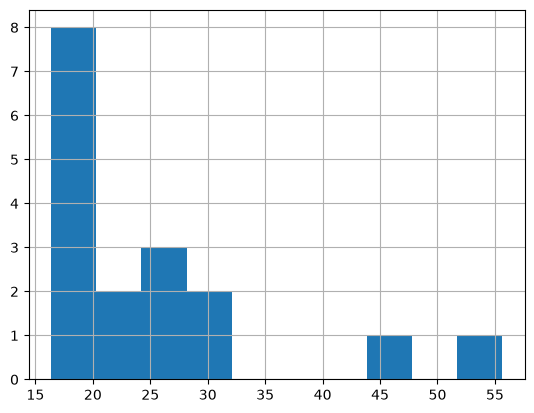

In [22]:
temp_very_heavy_rain = very_heavy_rain.drop(index=24872)
temp_very_heavy_rain["rain_1h"].hist()

Como la distribucion es sesgada se va a imputar con la media

In [23]:
very_heavy_rain.loc[24872, "rain_1h"] = np.nan
median = very_heavy_rain["rain_1h"].median()
median

np.float64(21.42)

In [24]:
metro.loc[24872, "rain_1h"] = median
metro.loc[24872]

holiday                                NaN
temp                                302.11
rain_1h                              21.42
snow_1h                                0.0
clouds_all                              75
weather_main                          Rain
weather_description        very heavy rain
date_time              2016-07-11 17:00:00
traffic_volume                        5535
Name: 24872, dtype: object

### snow_1h column

snow_1h es la cantidad de nieve que cayo en una hora en mm

no hay valores raros en esta columna

In [25]:
max_snow_1h = metro["snow_1h"].max()
min_snow_1h = metro["snow_1h"].min()
print(f"max snow_1h: {max_snow_1h}")
print(f"min snow_1h: {min_snow_1h}")

max snow_1h: 0.51
min snow_1h: 0.0


In [26]:
metro.columns

Index(['holiday', 'temp', 'rain_1h', 'snow_1h', 'clouds_all', 'weather_main',
       'weather_description', 'date_time', 'traffic_volume'],
      dtype='str')

### clouds_all column

clouds_all es el porcentage de nubosidad

Los valores van de 0 a 100 por lo que no hay ningun problema con esta columna

In [27]:
max_clouds_all = metro["clouds_all"].max()
min_clouds_all = metro["clouds_all"].min()
print(f"max clouds_all: {max_clouds_all}")
print(f"min clouds_all: {min_clouds_all}")

max clouds_all: 100
min clouds_all: 0


### weather_description and weather_main columns

In [28]:
metro["weather_description"] = (
    metro["weather_description"]
        .str.strip()
        .str.lower()
)

metro["weather_description"].unique()

<StringArray>
[                   'scattered clouds',                       'broken clouds',
                     'overcast clouds',                        'sky is clear',
                          'few clouds',                          'light rain',
             'light intensity drizzle',                                'mist',
                                'haze',                                 'fog',
               'proximity shower rain',                             'drizzle',
                       'moderate rain',                'heavy intensity rain',
              'proximity thunderstorm',        'thunderstorm with light rain',
    'proximity thunderstorm with rain',                          'heavy snow',
             'heavy intensity drizzle',                                'snow',
        'thunderstorm with heavy rain',                       'freezing rain',
                         'shower snow',                 'light rain and snow',
         'light intensity shower rain'

In [29]:
metro["weather_main"].unique()

<StringArray>
[      'Clouds',        'Clear',         'Rain',      'Drizzle',
         'Mist',         'Haze',          'Fog', 'Thunderstorm',
         'Snow',       'Squall',        'Smoke']
Length: 11, dtype: str

cada etiqueta de weather_description solo pertenece a una etiqueta de weather_main

In [30]:
cross_table = pd.crosstab(metro["weather_description"], metro["weather_main"])
cross_table

weather_main,Clear,Clouds,Drizzle,Fog,Haze,Mist,Rain,Smoke,Snow,Squall,Thunderstorm
weather_description,,,,,,,,,,,
broken clouds,0,4663,0,0,0,0,0,0,0,0,0
drizzle,0,0,651,0,0,0,0,0,0,0,0
few clouds,0,1956,0,0,0,0,0,0,0,0,0
fog,0,0,0,912,0,0,0,0,0,0,0
freezing rain,0,0,0,0,0,0,2,0,0,0,0
haze,0,0,0,0,1360,0,0,0,0,0,0
heavy intensity drizzle,0,0,64,0,0,0,0,0,0,0,0
heavy intensity rain,0,0,0,0,0,0,467,0,0,0,0
heavy snow,0,0,0,0,0,0,0,0,616,0,0


### date_time column

Hora en que fue recolectada la data en CST time

hay filas que tienen el mismo timestamp, eso es incorrecto

In [31]:
metro["date_time"].value_counts()

date_time
2013-04-18 22:00:00    6
2013-05-19 10:00:00    6
2012-10-25 15:00:00    5
2012-10-26 04:00:00    5
2012-11-11 04:00:00    5
                      ..
2018-09-30 19:00:00    1
2018-09-30 20:00:00    1
2018-09-30 21:00:00    1
2018-09-30 22:00:00    1
2018-09-30 23:00:00    1
Name: count, Length: 40575, dtype: int64

In [32]:
metro.index[metro["date_time"] == "2013-04-18 22:00:00"]

Index([5249, 5250, 5251, 5252, 5253, 5254], dtype='int64')

Para las filas con el timestamp 2013-04-18 22:00:00 las unicas columnas que cambian son weather_main y weather_description

In [33]:
metro.loc[5249: 5254]

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
5249,NaN,274.79,0.0,0.0,90,Mist,mist,2013-04-18 22:00:00,1532
5250,NaN,274.79,0.0,0.0,90,Drizzle,light intensity drizzle,2013-04-18 22:00:00,1532
5251,NaN,274.79,0.0,0.0,90,Rain,light rain,2013-04-18 22:00:00,1532
5252,NaN,274.79,0.0,0.0,90,Rain,moderate rain,2013-04-18 22:00:00,1532
5253,NaN,274.79,0.0,0.0,90,Snow,heavy snow,2013-04-18 22:00:00,1532
5254,NaN,274.79,0.0,0.0,90,Snow,snow,2013-04-18 22:00:00,1532


filas con date_time duplicado:

In [34]:
metro["date_time"].duplicated(keep=False).sum()

np.int64(13042)

valores de date_time duplicados:

In [35]:
metro.loc[metro["date_time"].duplicated(), "date_time"].nunique()

5430

filas en donde date_time se repite y alguna columna diferente a weather_description y weather_main es diferente a su duplicado

In [36]:
columnas = [
    "holiday",
    "temp",
    "rain_1h",
    "snow_1h",
    "clouds_all",
    "traffic_volume"
]

fechas_repetidas = metro.groupby("date_time").filter(
    lambda x: len(x) > 1
)

variacion_repetidos = (
    fechas_repetidas.groupby("date_time")[columnas]
    .nunique()
)

# Timestamps donde alguna variable NO meteorológica cambia
variacion_repetidos[(variacion_repetidos > 1).any(axis=1)]


,holiday,temp,rain_1h,snow_1h,clouds_all,traffic_volume
date_time,,,,,,
2012-11-04 01:00:00,0,2,1,1,1,1
2014-01-03 20:00:00,0,2,1,1,1,1
2014-01-09 16:00:00,0,2,1,1,2,1
2014-01-11 16:00:00,0,2,1,1,2,1
2014-01-15 00:00:00,0,2,1,1,2,1
...,...,...,...,...,...,...
2016-12-16 18:00:00,0,2,1,1,1,1
2016-12-17 01:00:00,0,2,1,1,1,1
2016-12-18 14:00:00,0,2,1,1,1,1


no hay ningun conjunto de filas repetidas en las que traffic_volume es diferente a su fila repetida
por lo que podemos asumir que la API del clima fallo

In [37]:
variacion_repetidos[variacion_repetidos["traffic_volume"] > 1]

,holiday,temp,rain_1h,snow_1h,clouds_all,traffic_volume
date_time,,,,,,


date_time es igual en ambas filas pero temp y clouds_all son diferentes.
Como tienen un diferente valor para una misma hora y cada columna numerica mide su respectivo promedio en una hora,para todos estos casos se van a promediar los valor diferentes entre los repetidos para modificar las filas y quedarnos solo con uno.

In [38]:
metro[metro["date_time"] == "2014-01-09 16:00:00"]

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
11337,NaN,265.73,0.0,0.0,40,Clouds,scattered clouds,2014-01-09 16:00:00,6421
11338,NaN,266.47,0.0,0.0,64,Clouds,broken clouds,2014-01-09 16:00:00,6421


In [39]:
columnas = ["temp", "rain_1h", "snow_1h", "clouds_all"]

metro[columnas] = (
    metro.groupby("date_time")[columnas]
      .transform("mean")
)

In [40]:
metro.duplicated(keep=False).sum()

np.int64(130)

In [41]:
metro = metro.drop_duplicates()
metro.duplicated(keep=False).sum()

np.int64(0)

ahora todas las filas que tienen date_time duplicado unicamente difieren en weather_description y/o weather_main

In [42]:
columnas = [
    "holiday",
    "temp",
    "rain_1h",
    "snow_1h",
    "clouds_all",
    "traffic_volume"
]

fechas_repetidas = metro.groupby("date_time").filter(
    lambda x: len(x) > 1
)

variacion_repetidos = (
    fechas_repetidas.groupby("date_time")[columnas]
    .nunique()
)

# Timestamps donde alguna variable NO meteorológica cambia
variacion_repetidos[(variacion_repetidos > 1).any(axis=1)]

,holiday,temp,rain_1h,snow_1h,clouds_all,traffic_volume
date_time,,,,,,


Establecer una relacion de severidad para decidir con que valor de weather_main quedarme no parece ser buena idea, ya que clear y snow tienen practicamente la misma severidad, cuando la intuicion nos dice lo contrario

In [43]:
metro.groupby("weather_main")["traffic_volume"].mean().sort_values(ascending=False)

weather_main
Clouds          3617.045319
Haze            3501.285504
Rain            3316.996467
Drizzle         3290.929593
Smoke           3237.650000
Clear           3055.735173
Snow            3013.618550
Thunderstorm    3001.651163
Mist            2933.081987
Fog             2703.720395
Squall          2061.750000
Name: traffic_volume, dtype: float64

In [44]:
date_duplicated = metro[metro["date_time"].duplicated(keep=False)]
date_duplicated

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
178,NaN,281.25,0.0,0.0,99.0,Rain,light rain,2012-10-10 07:00:00,6793
179,NaN,281.25,0.0,0.0,99.0,Drizzle,light intensity drizzle,2012-10-10 07:00:00,6793
180,NaN,280.10,0.0,0.0,99.0,Rain,light rain,2012-10-10 08:00:00,6283
181,NaN,280.10,0.0,0.0,99.0,Drizzle,light intensity drizzle,2012-10-10 08:00:00,6283
182,NaN,279.61,0.0,0.0,99.0,Rain,light rain,2012-10-10 09:00:00,5680
...,...,...,...,...,...,...,...,...,...
48112,NaN,285.17,0.0,0.0,90.0,Drizzle,light intensity drizzle,2018-09-27 07:00:00,6589
48192,NaN,283.48,0.0,0.0,90.0,Rain,light rain,2018-09-30 14:00:00,4380
48193,NaN,283.48,0.0,0.0,90.0,Drizzle,light intensity drizzle,2018-09-30 14:00:00,4380
48194,NaN,283.84,0.0,0.0,75.0,Rain,proximity shower rain,2018-09-30 15:00:00,4302


In [45]:
date_duplicated["date_time"].value_counts().head(20)

date_time
2013-04-18 22:00:00    6
2013-05-19 10:00:00    6
2012-10-25 15:00:00    5
2012-10-26 04:00:00    5
2012-11-11 04:00:00    5
2012-11-11 09:00:00    5
2012-12-16 09:00:00    5
2012-12-16 19:00:00    5
2012-12-16 21:00:00    5
2013-02-11 10:00:00    5
2013-04-11 01:00:00    5
2013-04-18 23:00:00    5
2013-04-22 19:00:00    5
2013-05-19 06:00:00    5
2013-05-19 08:00:00    5
2013-05-19 09:00:00    5
2013-05-20 17:00:00    5
2013-05-20 18:00:00    5
2013-05-21 23:00:00    5
2013-05-31 00:00:00    5
Name: count, dtype: int64

In [46]:
date_duplicated[date_duplicated["date_time"] == "2013-05-19 08:00:00"]

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
6152,NaN,286.37,0.0,0.0,90.0,Thunderstorm,thunderstorm with rain,2013-05-19 08:00:00,1700
6153,NaN,286.37,0.0,0.0,90.0,Mist,mist,2013-05-19 08:00:00,1700
6154,NaN,286.37,0.0,0.0,90.0,Thunderstorm,proximity thunderstorm,2013-05-19 08:00:00,1700
6155,NaN,286.37,0.0,0.0,90.0,Rain,moderate rain,2013-05-19 08:00:00,1700
6156,NaN,286.37,0.0,0.0,90.0,Rain,light rain,2013-05-19 08:00:00,1700


In [47]:
def elegir_weather(group, df):
    # Frecuencia de cada weather_main
    frecuencias = group["weather_main"].value_counts()

    # Frecuencia máxima
    max_freq = frecuencias.max()

    # Categorías que tienen la moda
    modas = frecuencias[frecuencias == max_freq].index.tolist()

    # Caso: existe una única moda
    if len(modas) == 1:
        elegido = modas[0]

    # Caso: hay empate
    else:
        # El timestamp del grupo está en group.name
        timestamp = group.name

        # Filas que no pertenecen al grupo actual
        fuera = df[~df.index.isin(group.index)].copy()

        # Solo nos interesan las categorías empatadas
        candidatos = fuera[
            fuera["weather_main"].isin(modas)
        ].copy()

        # Distancia temporal respecto al timestamp actual
        candidatos["distancia"] = (
            candidatos["date_time"] - timestamp
        ).abs()

        # El índice original será el criterio secundario
        candidatos["_orden_original"] = candidatos.index

        # Primero menor distancia temporal.
        # En caso de empate, menor índice original.
        candidatos = candidatos.sort_values(
            ["distancia", "_orden_original"]
        )

        elegido = candidatos["weather_main"].iloc[0]

    # Obtener la fila original que vamos a conservar
    fila = group[group["weather_main"] == elegido].iloc[0].copy()

    # Volver a agregar explícitamente date_time
    fila["date_time"] = group.name

    return fila


In [48]:
metro_colapsado = (
    metro
    .groupby("date_time", group_keys=False)
    .apply(lambda x: elegir_weather(x, metro))
    .reset_index(drop=True)
)   

In [49]:
metro_colapsado[metro_colapsado["date_time"].duplicated(keep=False)]

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,traffic_volume,date_time


In [ ]:
len(metro_colapsado)

40575

In [54]:
metro_colapsado = metro_colapsado[["holiday", "temp", "rain_1h", "snow_1h", "clouds_all", "weather_main", "weather_description", "date_time", "traffic_volume"]]

In [55]:
metro_colapsado.head()

,holiday,temp,rain_1h,snow_1h,clouds_all,weather_main,weather_description,date_time,traffic_volume
0,NaN,288.28,0.0,0.0,40.0,Clouds,scattered clouds,2012-10-02 09:00:00,5545
1,NaN,289.36,0.0,0.0,75.0,Clouds,broken clouds,2012-10-02 10:00:00,4516
2,NaN,289.58,0.0,0.0,90.0,Clouds,overcast clouds,2012-10-02 11:00:00,4767
3,NaN,290.13,0.0,0.0,90.0,Clouds,overcast clouds,2012-10-02 12:00:00,5026
4,NaN,291.14,0.0,0.0,75.0,Clouds,broken clouds,2012-10-02 13:00:00,4918


In [57]:
path = "/home/bryan/data_mining/data/procesed/metro.csv"
metro_colapsado.to_csv(path, index=False)